# Лабораторна робота № 6
## Конвеєр інтелектуального аналізу даних та інтерпретація моделі

**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали

---

### Постановка

Ви — аналітик інтернет-провайдера. Маркетинг просить модель, яка **в момент
звернення клієнта** оцінює ризик, що той розірве договір протягом кварталу.
Модель потрібна не заради числа: за її підказкою відділ утримання
телефонуватиме людям і пропонуватиме знижку. Тому від вас хочуть **дві речі**:

1. чесну оцінку якості;
2. **пояснення**, чому модель вважає конкретного клієнта ризиковим.

Вам видали вивантаження з CRM. Воно зроблене не для аналізу, а для звітності,
тому в ньому є все підряд — зокрема й те, чого в момент прогнозу ще не існує.

> **Попередження, яке варто прочитати двічі.** Перший результат, який ви
> отримаєте, буде прекрасним. Робота полягає в тому, щоб з'ясувати, чому
> йому не можна вірити, і скільки залишиться після того, як ви приберете
> все зайве.

### Що здаєте

Цей ноутбук із заповненими комірками, виконаними **згори вниз без помилок**,
і відповідями на питання розділу 15.

### Як оцінюється

| Частина | Що оцінюється | Балів |
|---|---|---|
| 1 | Конвеєр: обробка, витік, чесне число, вибір методу | 2,0 |
| 2 | Інтерпретація: важливість, PDP, SHAP | 1,5 |
| 3 | Звіт: обґрунтування рішень і виявлені хибні інтерпретації | 0,5 |

Штраф −0,5 бала, якщо ноутбук не виконується згори вниз на чистому ядрі.

**Виконав:** Бубельник Юрій · **Група:** ШІ-31 · **Варіант:** 2


---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Файл даних підтягнеться сам.

In [1]:
STUDENT_NAME = 'Бубельник Юрій'
GROUP = 'ШІ-31'
LIST_NUMBER = 2
VARIANT = (LIST_NUMBER - 1) % 30 + 1
DATA = 'lr6_варіант_%02d.csv' % VARIANT
print(STUDENT_NAME, GROUP, 'варіант', VARIANT, DATA)

Бубельник Юрій ШІ-31 варіант 2 lr6_варіант_02.csv


> Файли варіантів лежать у теці `дані/` поряд із ноутбуком. Якщо викладач
> призначив вам інший варіант — перепишіть `VARIANT` вручну і зазначте це у звіті.

In [ ]:
import importlib.util
REQUIRED = {'pandas': 'pandas', 'numpy': 'numpy', 'scikit-learn': 'sklearn',
            'matplotlib': 'matplotlib', 'shap': 'shap'}
missing = [p for p, m in REQUIRED.items() if importlib.util.find_spec(m) is None]
assert not missing, 'Встановіть залежності: uv sync; або pip install ' + ' '.join(missing)
print('Залежності доступні')

Залежності доступні


In [3]:
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
import os, re, json, time, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import (RepeatedStratifiedKFold, cross_val_score,
                                     train_test_split)
from sklearn.inspection import permutation_importance, partial_dependence
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report

SEED = 42
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 60)
print('усе імпортовано')
from pathlib import Path
from sklearn.tree import DecisionTreeClassifier
from sklearn.base import BaseEstimator, TransformerMixin, clone
from scipy.stats import t
from threadpoolctl import threadpool_limits
from IPython.display import display, Markdown
thread_limits = threadpool_limits(limits=2)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .2})
FIGURES = Path('lr6_графіки')
FIGURES.mkdir(exist_ok=True)
def finish_plot(name):
    plt.tight_layout()
    plt.savefig(FIGURES / (name + '.png'), dpi=140, bbox_inches='tight')
    plt.show()


усе імпортовано


---
## 1. Три рішення, які ухвалюють ДО того, як торкнутись даних

Нагадування з лекції 7: кроки 1–3 алгоритму виконуються перш ніж
ви напишете хоч один рядок обробки. Якщо обрати метрику після того, як
побачив результати, ви оберете ту, яка показала більше.

### Завдання 1.1

Заповніть три змінні нижче і **обґрунтуйте кожну** одним реченням у коментарі.

In [4]:
TYPE_OF_TASK = 'класифікація'  # Передбачаємо бінарну подію розірвання договору.
METRIC = 'AUC'  # Оцінюємо ранжування ризику без вибору порога, за дисбалансу класів.
CV_SCHEME = 'стратифікована 5-кратна, 4 повтори'  # Зберігаємо частки класів і вимірюємо розкид.
print(TYPE_OF_TASK, METRIC, CV_SCHEME)
print('Це внутрішня перевірка на наявному CRM; перенесення в часі/між філіями потребує окремої перевірки.')

класифікація AUC стратифікована 5-кратна, 4 повтори
Це внутрішня перевірка на наявному CRM; перенесення в часі/між філіями потребує окремої перевірки.


> **Підказка до METRIC.** Подивіться на частку відтоку в наступному розділі.
> Якщо вона далека від 50 %, подумайте, яку точність дасть модель
> «ніхто не піде» — і чи варта вона чогось.

---
## 2. Перший погляд на дані

### Завдання 2.1

Прочитайте файл і дайте відповідь на чотири питання: скільки рядків і стовпців,
яка частка відтоку, скільки стовпців має невизначений тип, де найбільше пропусків.

In [5]:
raw = pd.read_csv(os.path.join('дані', DATA), encoding='utf-8-sig')
TARGET = 'відтік'

print('розмір:', raw.shape)
print('частка відтоку: %.3f' % raw[TARGET].mean())
print()
print('типи стовпців:', raw.dtypes.astype(str).value_counts().to_dict())

розмір: (1200, 26)
частка відтоку: 0.280

типи стовпців: {'str': 14, 'float64': 7, 'int64': 5}


In [6]:
passport = pd.DataFrame({'тип': raw.dtypes.astype(str), 'унікальних': raw.nunique(),
                        '% пропусків': raw.isna().mean() * 100,
                        'приклад': [raw[c].dropna().iloc[0] for c in raw]})
display(passport.sort_values('% пропусків', ascending=False))
print('Текстових стовпців:', len(raw.select_dtypes(include=['object', 'string']).columns))
print('Точність «ніхто не піде»: %.3f; повнота відтоку: 0' % (1 - raw[TARGET].mean()))
assert raw.id_клієнта.is_unique

,тип,унікальних,% пропусків,приклад
дата_розірвання,str,278,72.00,2024-04-20
код_причини_закриття,str,5,72.00,ЦІН-02
середній_час_відповіді_хв,float64,263,35.75,13.8
трафік_ГБ,str,953,5.00,96.2
щомісячний_платіж,str,1122,4.00,304.94
аварій_на_ділянці_за_квартал,float64,6,3.00,3.0
стать,str,6,0.00,ж
місто,str,6,0.00,Самбір
id_клієнта,str,1200,0.00,K20000
вік,float64,61,0.00,42.0


Текстових стовпців: 14
Точність «ніхто не піде»: 0.720; повнота відтоку: 0


### Завдання 2.2 — три способи, якими дані вже зіпсовані

У вивантаженні є щонайменше три проблеми, кожна з яких тихо зламає модель.
Знайдіть їх і **назвіть конкретні стовпці**.

1. Числова колонка, у якій частина значень записана **текстом**.
2. Колонка, у якій Excel перетворив число на **дату**.
3. Колонка, пропуски в якій **не випадкові** — їхня наявність сама щось означає
   (механізм MNAR за класифікацією Рубіна, розділ 7.2 конспекту).

In [7]:
display(raw.loc[raw['щомісячний_платіж'].str.contains('грн', na=False), ['щомісячний_платіж']].head())
display(raw.loc[raw['трафік_ГБ'].str.contains('1900-', na=False), ['трафік_ГБ']])
display(pd.crosstab(raw['середній_час_відповіді_хв'].isna(), raw['кількість_звернень_у_підтримку']))
assert (raw['середній_час_відповіді_хв'].isna() == (raw['кількість_звернень_у_підтримку'] == 0)).all()

,щомісячний_платіж
4,210.63 грн
132,384.39 грн
137,266.78 грн
165,289.64 грн
221,268.59 грн


,трафік_ГБ
617,1900-01-02 00:00:00
813,1900-01-02 00:00:00
1008,1900-01-01 00:00:00


кількість_звернень_у_підтримку,0,1,2,3,4,5,6
середній_час_відповіді_хв,,,,,,,
False,0,451,222,77,16,4,1
True,429,0,0,0,0,0,0


In [8]:
PROBLEM_TEXT_IN_NUMBER = 'щомісячний_платіж'
PROBLEM_EXCEL_DATE = 'трафік_ГБ'
PROBLEM_MNAR = 'середній_час_відповіді_хв'
MNAR_MEANING = ('Усі 429 пропусків відповідають відсутності звернень: час відповіді не визначений. '
                'Це структурна відсутність, а не випадкова втрата. Шаблон називає її MNAR, '
                'але за спостережуваним числом звернень механізм пояснений; MNAR строго не доведено.')
print(MNAR_MEANING)

Усі 429 пропусків відповідають відсутності звернень: час відповіді не визначений. Це структурна відсутність, а не випадкова втрата. Шаблон називає її MNAR, але за спостережуваним числом звернень механізм пояснений; MNAR строго не доведено.


---
## 3. Будуємо матрицю ознак

Перетворення сирої таблиці на матрицю `X` — це фаза 3 CRISP-DM. Усі рішення
тут приймаються **явно** і записуються, бо потім їх доведеться захищати.

### Завдання 3.1

Допишіть `to_number` і `build_X`.

* `to_number` має витягати число з тексту `'350.5 грн'`, **не** перетворювати
  дату на число і повертати `NaN` там, де числа немає.
* `build_X` для кожного стовпця вирішує: число, категорія чи викинути.
  Дата підключення має стати **числом** (напр. порядковим номером дня) —
  інакше модель її не з'їсть.

In [9]:
def to_number(s):
    def one(v):
        if pd.isna(v) or isinstance(v, (datetime.date, datetime.datetime, pd.Timestamp, np.datetime64)):
            return np.nan
        if isinstance(v, (int, float, np.number)):
            return float(v) if np.isfinite(v) else np.nan
        text = str(v).strip().replace('\u00a0', '').replace(' ', '')
        # Дату відхиляємо ДО пошуку першого числа, включно з Excel-датою в тексті.
        if re.match(r'^\d{4}[-/]\d{1,2}[-/]\d{1,2}', text) or re.match(r'^\d{1,2}[./]\d{1,2}[./]\d{2,4}', text):
            return np.nan
        m = re.search(r'[-+]?\d+(?:[.,]\d+)?(?:[eE][-+]?\d+)?', text)
        return float(m.group().replace(',', '.')) if m else np.nan
    return s.map(one).astype(float)

_t = pd.Series([1, '350.5 грн', '2,75', datetime.datetime(1900, 1, 11), None,
                'немає', '1900-01-02 00:00:00', '11.01.1900'])
_r = to_number(_t)
assert np.allclose(_r[:3], [1, 350.5, 2.75]) and _r[3:].isna().all()
print('to_number: усі перевірки пройдено')

to_number: усі перевірки пройдено


In [10]:
DROP_ALWAYS = ['id_клієнта']

def build_X(d, drop):
    # Лише детермінований розбір: медіани, масштаби і словник категорій навчаються у Pipeline.
    X = pd.DataFrame(index=d.index)
    log = []
    for c in d:
        if c in drop or c == TARGET:
            continue
        if c == 'дата_підключення':
            X[c] = (pd.to_datetime(d[c], errors='coerce') - pd.Timestamp('1970-01-01')).dt.days.astype(float)
            kind = 'дата -> день'
        elif pd.api.types.is_numeric_dtype(d[c]):
            X[c] = d[c].astype(float)
            kind = 'число'
        else:
            parsed = to_number(d[c])
            # У кодах і назвах філій цифри позначають категорії, а не величини.
            is_code = c in ['філія', 'код_тарифного_плану', 'код_причини_закриття']
            if not is_code and parsed.notna().sum() / max(d[c].notna().sum(), 1) > .8:
                X[c] = parsed
                kind = 'текст -> число'
            else:
                s = d[c].astype('string').str.strip().str.lower().str.replace(r'\s+', ' ', regex=True)
                if c == 'стать':
                    s = s.replace({'чол': 'ч', 'жін': 'ж'})
                X[c] = s.astype(object).where(s.notna(), np.nan).astype('category')
                kind = 'категорія'
        log.append({'ознака': c, 'дія': kind, 'пропусків після розбору': X[c].isna().sum()})
    return X, pd.DataFrame(log)

X_all, log = build_X(raw, DROP_ALWAYS)
y = raw[TARGET].astype(int)
display(log)
print('Матриця:', X_all.shape)

,ознака,дія,пропусків після розбору
0,вік,число,0
1,стать,категорія,0
2,місто,категорія,0
3,філія,категорія,0
4,тариф,категорія,0
5,тип_підключення,категорія,0
6,спосіб_оплати,категорія,0
7,автоплатіж,категорія,0
8,кількість_послуг,число,0
9,місяців_обслуговування,число,0


Матриця: (1200, 24)


### Завдання 3.2 — конвеєр

Зберіть `make_pipe(X, clf)`: колонковий перетворювач (числові — медіана плюс
стандартизація; категоріальні — мода плюс одиничне кодування) і модель.

> **Чому саме так.** Відповідь у розділі 10 конспекту: усе, що має `fit`,
> мусить опинитись **усередині** конвеєра, інакше крос-валідація бреше.
> Зверніть увагу на `handle_unknown='ignore'` — без нього модель упаде на
> категорії, якої не було в навчальній згортці.

In [11]:
def make_pipe(X, clf):
    nums = X.select_dtypes(include='number').columns.tolist()
    cats = [c for c in X if c not in nums]
    numeric = Pipeline([('impute', SimpleImputer(strategy='median', keep_empty_features=True)),
                        ('scale', StandardScaler())])
    category = Pipeline([('impute', SimpleImputer(strategy='most_frequent', keep_empty_features=True)),
                         ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])
    prep = ColumnTransformer([('num', numeric, nums), ('cat', category, cats)], sparse_threshold=0)
    return Pipeline([('prep', prep), ('clf', clone(clf))])

def logreg():
    return LogisticRegression(max_iter=3000, random_state=SEED)

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=4, random_state=SEED)
splits = list(cv.split(X_all, y))
scores, timings = {}, {}
def evaluate(key, X, clf):
    start = time.perf_counter()
    a = cross_val_score(make_pipe(X, clf), X, y, cv=splits, scoring='roc_auc', error_score='raise')
    timings[key] = time.perf_counter() - start
    scores[key] = a
    return a

_s = cross_val_score(make_pipe(X_all, logreg()), X_all, y, cv=splits[:5], scoring='roc_auc', error_score='raise')
assert len(_s) == 5 and np.isfinite(_s).all()
print('Пробний прогін:', _s.mean())

Пробний прогін: 1.0


---
## 4. Перший результат

Запустіть модель на **всьому, що є**, — саме так робить дев'ять аналітиків
із десяти, коли їм дали вивантаження і попросили «подивитись, чи взагалі
щось передбачається».

In [12]:
auc_naive = evaluate('naive', X_all, logreg())
print('AUC %.4f ± %.4f; %.2f с / 20 навчань' % (auc_naive.mean(), auc_naive.std(), timings['naive']))

AUC 1.0000 ± 0.0000; 0.86 с / 20 навчань


### Завдання 4.1

Подивіться на число і на таблицю орієнтирів AUC з розділу 4.4 конспекту.

Запишіть у `FIRST_REACTION` одне речення: що саме це число означає
і яка з двох причин високої AUC, найімовірніше, спрацювала.

In [13]:
FIRST_REACTION = f'AUC {auc_naive.mean():.4f}: майже ідеальне ранжування, але CRM містить наслідки розірвання; найімовірніша причина — витік.'
print(FIRST_REACTION)

AUC 1.0000: майже ідеальне ранжування, але CRM містить наслідки розірвання; найімовірніша причина — витік.


---
## 5. Шукаємо витік

Чотири типи витоку (розділ 9.1 конспекту) і засіб проти кожного:

| Тип | Засіб |
|---|---|
| цільовий | чек-ліст: чи існує значення в момент прогнозу |
| препроцесинговий | конвеєр |
| часовий | часова схема перевірки |
| груповий | групова схема перевірки |

Починаємо з цільового.

### Завдання 5.1 — автоматичний детектор

Напишіть `leak_scan`: для кожного стовпця перевірте, чи **сам факт
заповненості** передбачає клас. Поріг `min_group` обов'язковий — без нього
детектор видає хибні спрацювання на колонках, заповнених у двох клієнтів.

In [14]:
def leak_scan(d, y, min_group=20):
    rows = []
    for c in d:
        if c == TARGET:
            continue
        present = d[c].notna()
        if present.sum() < min_group or (~present).sum() < min_group:
            continue
        a = roc_auc_score(y, present.astype(int))
        rows.append({'ознака': c, 'заповнено': int(present.sum()),
                     'частка_відтоку_де_заповнено': y[present].mean(),
                     'частка_відтоку_де_пропуск': y[~present].mean(),
                     'показник': max(a, 1-a)})
    return pd.DataFrame(rows).sort_values('показник', ascending=False)
scan = leak_scan(raw, y)
display(scan)
assert 'оцінка_ризику_менеджером' not in scan['ознака'].values

,ознака,заповнено,частка_відтоку_де_заповнено,частка_відтоку_де_пропуск,показник
4,код_причини_закриття,336,1.000000,0.000000,1.000000
5,дата_розірвання,336,1.000000,0.000000,1.000000
3,середній_час_відповіді_хв,771,0.308690,0.228438,0.545718
2,аварій_на_ділянці_за_квартал,1164,0.275773,0.416667,0.510169
1,трафік_ГБ,1140,0.280702,0.266667,0.501653
0,щомісячний_платіж,1152,0.280382,0.270833,0.500909


### Завдання 5.2 — цільовий витік

Стовпці з показником близько 1,0 заповнені **лише в одного класу**. Такий
стовпець записаний уже після того, як результат став відомий.

Випишіть їх у `TARGET_LEAK` і **для кожного поясніть одним реченням**, чому
його не існує в момент прогнозу.

In [15]:
TARGET_LEAK = ['код_причини_закриття', 'дата_розірвання']
LEAK_WHY = {'код_причини_закриття': 'Причину записують після рішення закрити договір.',
            'дата_розірвання': 'Фактична дата з’являється при розірванні; зараз договір чинний.'}
assert set(TARGET_LEAK) == set(scan.loc[scan['показник'] > .99, 'ознака'])
display(pd.Series(LEAK_WHY).to_frame('коли з’являється'))

,коли з’являється
код_причини_закриття,Причину записують після рішення закрити договір.
дата_розірвання,Фактична дата з’являється при розірванні; зара...


In [16]:
X2, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK)
auc2 = evaluate('target_removed', X2, logreg())
print('Без цільового витоку: %.4f ± %.4f' % (auc2.mean(), auc2.std()))

Без цільового витоку: 0.9665 ± 0.0059


### Завдання 5.3 — витік, якого детектор НЕ бачить

Число майже не впало. Отже головне ще попереду.

Детектор знаходить колонки, **формально** пов'язані з ціллю. Він безсилий
проти колонки, яка формально бездоганна, але якої **не існує в момент,
коли ухвалюється рішення** — або яка означає не те, що здається.

Перегляньте решту стовпців **очима** і поставте кожному питання з розділу 9.3:

> **Чи міг я знати це значення в ту мить, коли треба ухвалити рішення?**

Нагадування про момент прогнозу: клієнт щойно зателефонував, договір
**чинний**, рішення про знижку ухвалюється **зараз**.

In [17]:
# ----- ВАШ КОД: перегляньте список стовпців, що лишились -----
print(list(X2.columns))

['вік', 'стать', 'місто', 'філія', 'тариф', 'тип_підключення', 'спосіб_оплати', 'автоплатіж', 'кількість_послуг', 'місяців_обслуговування', 'швидкість_тарифу_Мбіт', 'щомісячний_платіж', 'знижка_відсоток', 'трафік_ГБ', 'кількість_звернень_у_підтримку', 'аварій_на_ділянці_за_квартал', 'середній_час_відповіді_хв', 'трафік_МБ', 'код_тарифного_плану', 'індекс_лояльності_CRM', 'дата_підключення', 'оцінка_ризику_менеджером']


In [18]:
HUMAN_LEAK = ['оцінка_ризику_менеджером']
HUMAN_LEAK_WHY = ('Оцінка заповнена для всіх, тому індикатор наявності сталий. '
                  'Менеджер оцінює ризик після спостереження поведінки клієнта; '
                  'у момент першого звернення цю ретроспективну оцінку використати не можна.')
X3, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK)
auc3 = evaluate('human_removed', X3, logreg())
print(HUMAN_LEAK_WHY)
print('Без оцінки людини: %.4f ± %.4f' % (auc3.mean(), auc3.std()))

Оцінка заповнена для всіх, тому індикатор наявності сталий. Менеджер оцінює ризик після спостереження поведінки клієнта; у момент першого звернення цю ретроспективну оцінку використати не можна.
Без оцінки людини: 0.8635 ± 0.0137


> Якщо тут число впало **суттєво** — ви знайшли головне. Якщо ні —
> перечитайте список стовпців ще раз: щось лишилось.

---
## 6. Артефакт збору даних

Лишилась найтонша перевірка. Якщо дані про два класи **збиралися
по-різному** — у різні періоди, різними людьми, за різними правилами —
модель вивчає спосіб запису, а не предмет. Жодна окрема колонка при цьому
не є витоком; витоком є вся таблиця.

Обчислювана перевірка з розділу 9.3: спробувати передбачити **не ціль,
а джерело**. Якщо за тими самими чесними ознаками добре вгадується філія
або період підключення — класи не порівнянні між собою.

### Завдання 6.1 — частка відтоку за філіями і за періодом

,mean,size
філія,,
Ф-01 Центр,0.439791,191
Ф-02 Захід,0.468421,190
Ф-03 Схід,0.196172,209
Ф-04 Південь,0.190722,194
Ф-05 Північ,0.197248,218
Ф-06 Приміська,0.212121,198


,mean,size
квартал,,
2023Q1,0.342282,149
2023Q2,0.277778,144
2023Q3,0.286624,157
2023Q4,0.296512,172
2024Q1,0.257353,136
2024Q2,0.246032,126
2024Q3,0.256250,160
2024Q4,0.269231,156


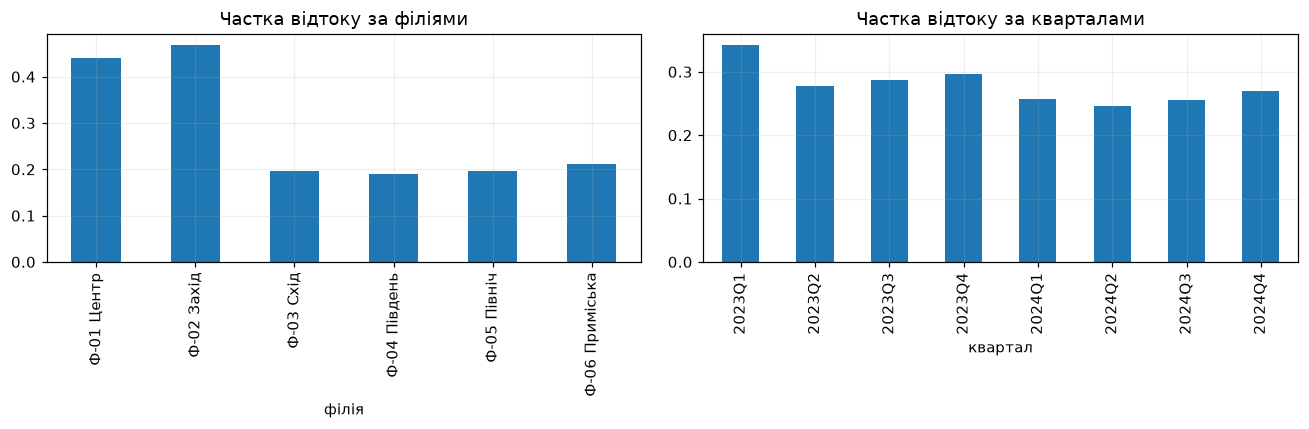

Сходинка між Ф-01/Ф-02 та рештою; квартали не показують такого різкого зламу.


In [19]:
branch_rates = raw.groupby('філія')[TARGET].agg(['mean', 'size'])
quarter_rates = raw.assign(квартал=pd.to_datetime(raw['дата_підключення']).dt.to_period('Q')).groupby('квартал')[TARGET].agg(['mean', 'size'])
display(branch_rates)
display(quarter_rates)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
branch_rates['mean'].plot.bar(ax=axes[0], title='Частка відтоку за філіями')
quarter_rates['mean'].plot.bar(ax=axes[1], title='Частка відтоку за кварталами')
finish_plot('01_джерело')
print('Сходинка між Ф-01/Ф-02 та рештою; квартали не показують такого різкого зламу.')

### Завдання 6.2 — передбачити джерело

Візьміть **ті самі чесні ознаки**, що й для моделі відтоку, і спробуйте
передбачити ними не `відтік`, а ознаку джерела: «клієнт із філії-підозрюваної»
або «підключений після дати-зламу».

Якщо AUC помітно вища за 0,5 — у ваших даних закодоване джерело.

In [20]:
SUSPECT = 'філія'
source = raw['філія'].isin(['Ф-01 Центр', 'Ф-02 Захід']).astype(int)
X4, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK + [SUSPECT])
auc_src = cross_val_score(make_pipe(X4, logreg()), X4, source, cv=cv, scoring='roc_auc', error_score='raise')
auc4 = evaluate('honest', X4, logreg())
print('Джерело: %.4f ± %.4f; відтік: %.4f ± %.4f' % (auc_src.mean(), auc_src.std(), auc4.mean(), auc4.std()))
print('Передбачуваність джерела разом зі сходинкою — підстава для аудиту збору, а не доказ причинності.')

Джерело: 0.6452 ± 0.0386; відтік: 0.8140 ± 0.0238
Передбачуваність джерела разом зі сходинкою — підстава для аудиту збору, а не доказ причинності.


### Завдання 6.3 — драбина

Зведіть усі чотири числа в одну таблицю і подивіться, **де саме** впало.

In [21]:
ladder = pd.DataFrame([
    {'крок': '1. усе підряд',               'ознак': X_all.shape[1], 'AUC': auc_naive.mean()},
    {'крок': '2. мінус цільовий витік',     'ознак': X2.shape[1],    'AUC': auc2.mean()},
    {'крок': '3. мінус оцінки людини',      'ознак': X3.shape[1],    'AUC': auc3.mean()},
    {'крок': '4. мінус артефакт збору',     'ознак': X4.shape[1],    'AUC': auc4.mean()},
]).set_index('крок')
display(ladder)

HONEST_AUC = float(auc4.mean())
print('чесне число: %.3f ± %.3f' % (HONEST_AUC, auc4.std()))

,ознак,AUC
крок,,
1. усе підряд,24,1.000000
2. мінус цільовий витік,22,0.966495
3. мінус оцінки людини,21,0.863468
4. мінус артефакт збору,20,0.813963


чесне число: 0.814 ± 0.024


### Завдання 6.4

Чи **правильно** викидати підозрюваний стовпець? Це не риторичне питання:
філія або дата підключення цілком можуть нести справжній сигнал
(щільна забудова, нові тарифи), а не лише артефакт.

Запишіть своє рішення і аргумент. Обидві відповіді приймаються — оцінюється
аргумент, а не вибір.

In [22]:
DECISION_ARTEFACT = 'викинути'
DECISION_WHY = ('Потрібне перенесення між філіями, а показник містить підозру на різні правила обліку. '
                'Вилучаю пряму філію, але місто й інші проксі можуть зберігати джерело; '
                'тому число є внутрішньою оцінкою, а не гарантією перенесення. Потрібен зовнішній тест.')
print(DECISION_ARTEFACT, DECISION_WHY)

викинути Потрібне перенесення між філіями, а показник містить підозру на різні правила обліку. Вилучаю пряму філію, але місто й інші проксі можуть зберігати джерело; тому число є внутрішньою оцінкою, а не гарантією перенесення. Потрібен зовнішній тест.


---
## 7. Крок 4 алгоритму: який метод узяти

Тепер, коли набір ознак чесний, можна обирати модель. Критеріїв чотири
(розділ 6 конспекту), і всі чотири вимірюються.

### Завдання 7.1

Порівняйте щонайменше чотири моделі **на тому самому наборі й тій самій
схемі перевірки**. Для кожної запишіть AUC, розкид і час на 100 навчань.

In [23]:
MODELS = {'логістична регресія': logreg(),
          'одне дерево': DecisionTreeClassifier(max_depth=6, min_samples_leaf=10, random_state=SEED),
          'випадковий ліс': RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=2),
          'гістограмний бустинг': HistGradientBoostingClassifier(max_iter=100, max_leaf_nodes=15, random_state=SEED)}
rows = []
for name, clf in MODELS.items():
    a = scores['honest'] if name == 'логістична регресія' else evaluate(name, X4, clf)
    scores[name] = a
    elapsed = timings['honest'] if name == 'логістична регресія' else timings[name]
    rows.append({'модель': name, 'AUC': a.mean(), 'SD': a.std(), 'с / 20 навчань': elapsed,
                 'с / 100 навчань (оцінка)': elapsed * 100 / len(a)})
cmp_models = pd.DataFrame(rows).set_index('модель')
display(cmp_models)
print('Час на 100 — екстраполяція фактичних 20 навчань, без повторних зайвих запусків.')

,AUC,SD,с / 20 навчань,с / 100 навчань (оцінка)
модель,,,,
логістична регресія,0.813963,0.023841,0.861396,4.306981
одне дерево,0.749239,0.024821,0.714397,3.571986
випадковий ліс,0.830172,0.029156,12.025562,60.127810
гістограмний бустинг,0.829726,0.025171,4.681933,23.409663


Час на 100 — екстраполяція фактичних 20 навчань, без повторних зайвих запусків.


### Завдання 7.2 — парне порівняння

Різниця середніх ще нічого не доводить: розкид між згортками може бути
більшим за саму різницю. Порівняйте **поскладово** (розділ 11.4 конспекту):
обидві моделі на тих самих поділах, далі різниця по кожній згортці.

Довірчий інтервал різниці накриває нуль → приріст у межах шуму.

In [24]:
def paired(a, b):
    # Поправка на залежність повторних CV: n_test/n_train = 1/4.
    # Це наближений corrected resampled t interval, не 20 незалежних вимірювань.
    d = np.asarray(b) - np.asarray(a)
    half = t.ppf(.975, len(d)-1) * np.sqrt((1/len(d) + 1/4) * d.var(ddof=1))
    return float(d.mean()), float(half)
base = scores['honest']
model_gains = {}
for name in ['випадковий ліс', 'гістограмний бустинг']:
    m, h = paired(base, scores[name])
    model_gains[name] = (m, h)
    print('%s: ΔAUC %+.4f; 95%% ДІ [%+.4f; %+.4f]' % (name, m, m-h, m+h))

випадковий ліс: ΔAUC +0.0162; 95% ДІ [-0.0052; +0.0376]
гістограмний бустинг: ΔAUC +0.0158; 95% ДІ [-0.0051; +0.0367]


In [25]:
CHOSEN_MODEL = 'випадковий ліс'
CHOSEN_WHY = (f'Ліс: AUC {scores[CHOSEN_MODEL].mean():.4f}; '
              f'логістична {base.mean():.4f}. Підходить для нелінійностей і взаємодій, '
              'потребує більше часу, але доступні важливості, PDP та TreeSHAP. '
              'Вибір враховує якість, час, відповідність даним та можливість пояснення; '
              'якщо бустинг кращий, ліс лишається прозорим навчальним компромісом для частини 2.')
print(CHOSEN_WHY)

Ліс: AUC 0.8302; логістична 0.8140. Підходить для нелінійностей і взаємодій, потребує більше часу, але доступні важливості, PDP та TreeSHAP. Вибір враховує якість, час, відповідність даним та можливість пояснення; якщо бустинг кращий, ліс лишається прозорим навчальним компромісом для частини 2.


---
## 8. Крок 6: конструювання ознак

Перш ніж брати складнішу модель, варто спитати, чи не бракує їй ознаки,
яку можна порахувати самому (розділ 8.2 конспекту).

### Завдання 8.1

Придумайте і додайте **щонайменше три** нові ознаки зі знання предметної
області. Кожну супроводьте коментарем: яку гіпотезу вона кодує.

Ідеї, з яких можна почати (але краще придумати свої):
відношення платежу до швидкості (переплата), трафік на гривню,
звернення на місяць обслуговування, чи є знижка взагалі,
скільки послуг на одного клієнта відносно середнього по філії.

In [26]:
def add_features(X):
    F = X.copy()
    # Плата за одиницю пропускної здатності: дорожчий інтернет може посилювати відтік.
    F['грн_за_Мбіт'] = F['щомісячний_платіж'] / F['швидкість_тарифу_Мбіт'].clip(lower=1)
    # Частота звернень за стажем: хронічні проблеми проти одноразової події.
    F['звернень_за_місяць'] = F['кількість_звернень_у_підтримку'] / F['місяців_обслуговування'].clip(lower=1)
    # Наявність знижки: можливий поріг чутливості до пропозиції утримання.
    F['є_знижка'] = (F['знижка_відсоток'] > 0).astype(float)
    return F
X5 = add_features(X4)
assert X5.shape[1] >= X4.shape[1] + 3
print('Було', X4.shape[1], 'стало', X5.shape[1])

Було 20 стало 23


In [27]:
auc5 = evaluate('features', X5, logreg())
feature_gain, feature_half = paired(base, auc5)
print('Нові ознаки: %.4f ± %.4f; Δ %+.4f; 95%% ДІ [%+.4f; %+.4f]' %
      (auc5.mean(), auc5.std(), feature_gain, feature_gain-feature_half, feature_gain+feature_half))

Нові ознаки: 0.8112 ± 0.0256; Δ -0.0027; 95% ДІ [-0.0072; +0.0017]


### Завдання 8.2

Порівняйте два шляхи покращення: **нові ознаки** проти **складнішої моделі**.
Який із них дав більше і якою ціною в секундах?

In [28]:
mg, mh = model_gains[CHOSEN_MODEL]
FEATURES_VS_MODEL = (f'Нові ознаки: ΔAUC {feature_gain:+.4f} ± {feature_half:.4f}, {timings["features"]:.2f} с. '
                     f'Ліс: ΔAUC {mg:+.4f} ± {mh:.4f}, {timings[CHOSEN_MODEL]:.2f} с. '
                     f'Більший середній приріст: {"ліс" if mg > feature_gain else "нові ознаки"}; '
                     'значущість слід читати за інтервалами, а не лише середніми.')
print(FEATURES_VS_MODEL)

Нові ознаки: ΔAUC -0.0027 ± 0.0045, 0.82 с. Ліс: ΔAUC +0.0162 ± 0.0214, 12.03 с. Більший середній приріст: ліс; значущість слід читати за інтервалами, а не лише середніми.


---
---
# ЧАСТИНА 2. Інтерпретація моделі

Перша частина дала **число**. Друга має дати **пояснення**: чому модель
вважає конкретного клієнта ризиковим, і чи можна на цьому пояснення
будувати дії відділу утримання.

Головна думка цієї частини: **кожен із трьох інструментів пояснення має
власний спосіб збрехати**, і ви маєте вміти ці випадки впізнавати.

Далі працюємо з однією навченою моделлю. Зафіксуємо її зараз.

In [29]:
# Для пояснень використовуємо вихідні чесні ознаки: похідні відношення
# змінюють зміст PDP при незалежному втручанні в їхні компоненти.
FINAL_X = X4
FINAL_CLF = MODELS[CHOSEN_MODEL]
assert not set(DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK + [SUSPECT]) & set(FINAL_X.columns)
Xtr, Xte, ytr, yte = train_test_split(FINAL_X, y, test_size=.3, stratify=y, random_state=SEED)
model = make_pipe(FINAL_X, FINAL_CLF).fit(Xtr, ytr)
auc_hold = roc_auc_score(yte, model.predict_proba(Xte)[:, 1])
print('AUC відкладених 30%%: %.4f' % auc_hold)
print('Це діагностичний поділ після дослідження всього набору; для фінального зовнішнього тесту потрібні нові дані.')

AUC відкладених 30%: 0.7923
Це діагностичний поділ після дослідження всього набору; для фінального зовнішнього тесту потрібні нові дані.


---
## 9. Важливість ознак: два способи і одна пастка

### Завдання 9.1 — вбудована важливість

`RandomForestClassifier.feature_importances_` рахує, наскільки кожна ознака
зменшувала неоднорідність при розбиттях. Виведіть топ-10.

> Увага: після одиничного кодування одна категоріальна ознака перетворюється
> на кілька стовпців. Щоб порівнювати з вихідними ознаками, важливості
> дамі-стовпців однієї ознаки треба **підсумувати**.

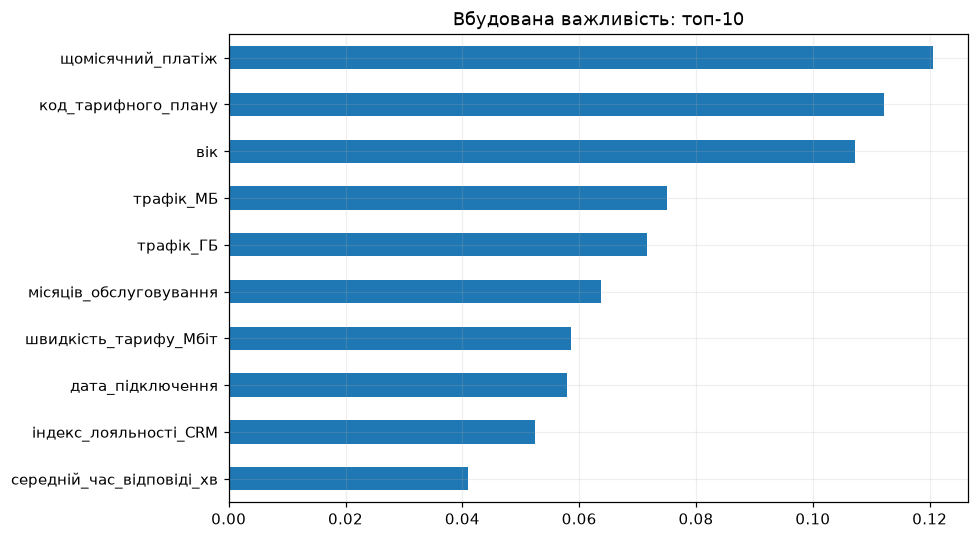

In [30]:
def original_feature_map(prep):
    # Точне зіставлення за довжинами блоків, без неоднозначного розбору підкреслень.
    nums = list(prep.transformers_[0][2])
    cats = list(prep.transformers_[1][2])
    enc = prep.named_transformers_['cat'].named_steps['encode']
    return nums + [c for c, values in zip(cats, enc.categories_) for _ in values]

orig_names = original_feature_map(model.named_steps['prep'])
gini_imp = pd.Series(model.named_steps['clf'].feature_importances_, index=orig_names).groupby(level=0).sum().sort_values(ascending=False)
assert abs(gini_imp.sum()-1) < 1e-8
gini_imp.head(10).sort_values().plot.barh(figsize=(9, 5), title='Вбудована важливість: топ-10')
finish_plot('02_вбудована_важливість')

### Завдання 9.2 — перестановочна важливість

Інший підхід: взяти навчену модель, **перемішати значення однієї ознаки**
у перевірковій частині й подивитись, наскільки впала якість. Впала сильно —
ознака потрібна; не впала — не потрібна.

Рахуйте на **перевірковій** частині: на навчальній перестановочна важливість
показує те саме перенавчання, що й вбудована.

In [31]:
perm = permutation_importance(model, Xte, yte, n_repeats=10,
                              random_state=SEED, scoring='roc_auc')
perm_imp = pd.Series(perm.importances_mean, index=FINAL_X.columns).sort_values(ascending=False)
display(perm_imp.head(10).to_frame('перестановочна важливість'))

,перестановочна важливість
вік,0.086372
місяців_обслуговування,0.031448
щомісячний_платіж,0.024607
трафік_МБ,0.019951
трафік_ГБ,0.011686
кількість_звернень_у_підтримку,0.007697
швидкість_тарифу_Мбіт,0.006969
автоплатіж,0.005411
знижка_відсоток,0.002932
аварій_на_ділянці_за_квартал,0.002483


### Завдання 9.3 — ПЕРША ХИБНА ІНТЕРПРЕТАЦІЯ

Порівняйте два списки поруч. Знайдіть ознаку, яка:

* входить у **топ-5 за вбудованою** важливістю;
* має перестановочну важливість **близьку до нуля або від'ємну**.

Така ознака є в кожному варіанті. Знайдіть її, назвіть і поясніть, чому
вбудована важливість її переоцінює.

> **Підказка.** Згадайте, як дерево обирає розбиття. Ознака з великою
> кількістю різних значень дає дереву багато можливих порогів, тож вона
> майже завжди знаходить розбиття, яке трохи зменшує неоднорідність —
> навіть якщо жодного зв'язку з ціллю немає.

In [32]:
importance_table = pd.concat([gini_imp.rename('вбудована'), perm_imp.rename('перестановочна'),
                             pd.Series(perm.importances_std, index=FINAL_X.columns, name='SD перестановок')], axis=1).sort_values('вбудована', ascending=False)
display(importance_table)

,вбудована,перестановочна,SD перестановок
щомісячний_платіж,0.120528,0.024607,0.017076
код_тарифного_плану,0.112217,0.000443,0.002061
вік,0.107282,0.086372,0.014519
трафік_МБ,0.075087,0.019951,0.007797
трафік_ГБ,0.071587,0.011686,0.007125
місяців_обслуговування,0.063772,0.031448,0.008157
швидкість_тарифу_Мбіт,0.058653,0.006969,0.014016
дата_підключення,0.057988,-0.003068,0.003462
індекс_лояльності_CRM,0.052374,-0.000960,0.002166
середній_час_відповіді_хв,0.040955,-0.002913,0.003403


In [33]:
FAKE_IMPORTANT = 'код_тарифного_плану'
FAKE_IMPORTANT_WHY = ('Код має 40 категорій і після one-hot дає багато кандидатів на розбиття. '
                      'Дерева обирають випадкові зменшення неоднорідності; сума MDI цих дамі завищена. '
                      'Велика кількість можливих розбиттів — перевага на навчанні, а не доказ користі на нових клієнтах.')
fake_rank = list(gini_imp.index).index(FAKE_IMPORTANT)+1
assert fake_rank <= 5 and abs(perm_imp[FAKE_IMPORTANT]) < .005
print('Місце за MDI:', fake_rank)
print(importance_table.loc[[FAKE_IMPORTANT]])
print(FAKE_IMPORTANT_WHY)
print('Додаткова шумна числова ознака: індекс_лояльності_CRM; її перевіркова важливість:', perm_imp['індекс_лояльності_CRM'])

Місце за MDI: 2
                     вбудована  перестановочна  SD перестановок
код_тарифного_плану   0.112217        0.000443         0.002061
Код має 40 категорій і після one-hot дає багато кандидатів на розбиття. Дерева обирають випадкові зменшення неоднорідності; сума MDI цих дамі завищена. Велика кількість можливих розбиттів — перевага на навчанні, а не доказ користі на нових клієнтах.
Додаткова шумна числова ознака: індекс_лояльності_CRM; її перевіркова важливість: -0.0009595168011009014


### Завдання 9.4 — ДРУГА ХИБНА ІНТЕРПРЕТАЦІЯ

У наборі є **дві ознаки, які вимірюють те саме в різних одиницях**.
Знайдіть цю пару (підказка: подивіться на кореляції між числовими ознаками).

Потім перевірте, що з нею робить перестановочна важливість:

1. запишіть важливість обох ознак пари в повній моделі;
2. **приберіть одну** з них, навчіть модель заново і подивіться на важливість
   тієї, що лишилась.

Поясніть, що сталось і чому.

In [34]:
corr = FINAL_X.select_dtypes(include='number').corr()
pairs = [(a,b,float(corr.loc[a,b])) for i,a in enumerate(corr) for b in corr.columns[i+1:] if abs(corr.loc[a,b])>.97]
display(pd.DataFrame(pairs, columns=['перша', 'друга', 'r']))

,перша,друга,r
0,трафік_ГБ,трафік_МБ,0.999659


In [35]:
DUP_PAIR = ['трафік_ГБ', 'трафік_МБ']
assert corr.loc[DUP_PAIR[0], DUP_PAIR[1]] > .99
reduced_cols = [c for c in FINAL_X if c != DUP_PAIR[1]]
reduced = make_pipe(Xtr[reduced_cols], FINAL_CLF).fit(Xtr[reduced_cols], ytr)
# Перемішуємо лише потрібну ознаку; решта колонок лишається незмінною.
def permute_one(estimator, X, yy, c, repeats=10):
    rng = np.random.default_rng(SEED)
    reference = roc_auc_score(yy, estimator.predict_proba(X)[:,1])
    vals = []
    for _ in range(repeats):
        Z = X.copy()
        Z[c] = rng.permutation(Z[c].to_numpy())
        vals.append(reference - roc_auc_score(yy, estimator.predict_proba(Z)[:,1]))
    return float(np.mean(vals))
dup_after = permute_one(reduced, Xte[reduced_cols], yte, DUP_PAIR[0])
print('У повній:', perm_imp[DUP_PAIR].to_dict(), 'без дубля:', dup_after)

У повній: {'трафік_ГБ': 0.011686226537711753, 'трафік_МБ': 0.01995106846592004} без дубля: 0.0474884361022974


In [36]:
DUP_EXPLANATION = (f'r={corr.loc[DUP_PAIR[0], DUP_PAIR[1]]:.5f}. Важливості ГБ/МБ: '
                   f'{perm_imp[DUP_PAIR[0]]:+.4f}/{perm_imp[DUP_PAIR[1]]:+.4f}; '
                   f'ГБ після вилучення МБ: {dup_after:+.4f}. Дублікати розподіляють сигнал; '
                   'важливість описує залежність конкретного навченого прогнозу від колонки. '
                   'Перенавчання змінює цю залежність; напрям зміни звіряємо з числами.')
print(DUP_EXPLANATION)

r=0.99966. Важливості ГБ/МБ: +0.0117/+0.0200; ГБ після вилучення МБ: +0.0475. Дублікати розподіляють сигнал; важливість описує залежність конкретного навченого прогнозу від колонки. Перенавчання змінює цю залежність; напрям зміни звіряємо з числами.


> **Що тут сталося.** Перестановочна важливість відповідає на питання
> «наскільки модель погіршиться **без цієї ознаки**». Коли та сама інформація
> є у двох колонках, перемішування однієї нічого не ламає: модель бере її
> з другої. Обидві виглядають непотрібними — хоча разом вони важливі.
>
> Це не вада методу, а точна відповідь на поставлене питання. Вада —
> в інтерпретації «важливість нуль, отже ознаку можна викинути».

---
## 10. Графіки часткової залежності

Важливість каже, **наскільки** ознака потрібна. Вона не каже, **як саме**
ознака впливає: більше — ризикованіше чи навпаки.

**Графік часткової залежності (PDP)** будується так: беремо всю вибірку,
підставляємо всім клієнтам одне й те саме значення ознаки, усереднюємо
прогноз; повторюємо для сітки значень.

### Завдання 10.1

Побудуйте PDP для трьох найважливіших **числових** ознак за перестановочною
важливістю. Для кожної скажіть словами, що означає форма кривої.

вік n= 360 ризик на краях/мінімум: 0.26612037037037034 0.5031851851851852 0.2523518518518518
До приблизно 35.2 років ризик спадає, далі зростає; старші клієнти мають вищий прогноз.


місяців_обслуговування n= 360 ризик на краях/мінімум: 0.36687037037037035 0.24284259259259264 0.24284259259259264
За більшого стажу ризик переважно нижчий: нові клієнти більш вразливі до відтоку.


щомісячний_платіж n= 345 ризик на краях/мінімум: 0.23459903381642513 0.44398067632850247 0.23322705314009665
Дорожче обслуговування переважно пов’язане з більшим ризиком; це не доказ ефекту зміни ціни.


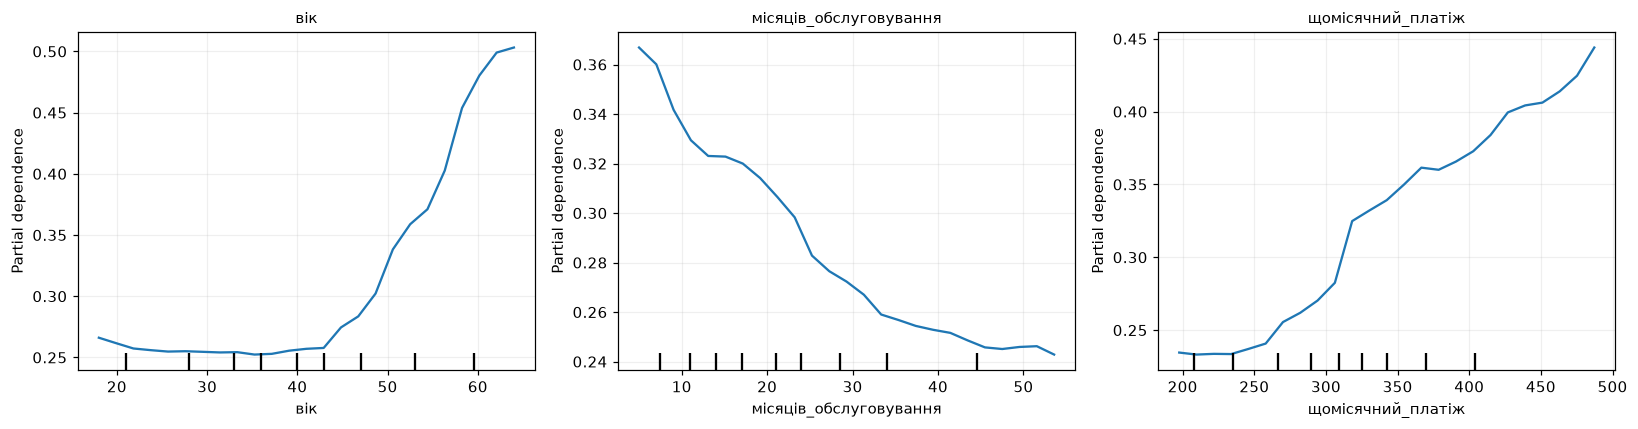

Для кожної ознаки PDP використано лише рядки, де вона заповнена; n наведено вище.


In [37]:
from sklearn.inspection import PartialDependenceDisplay
top_numeric = [c for c in perm_imp.index if pd.api.types.is_numeric_dtype(FINAL_X[c])][:3]
fig, axes = plt.subplots(1,3,figsize=(15,4))
pdp_results = {}
for c, ax in zip(top_numeric, axes):
    complete = Xte.loc[Xte[c].notna()]
    pdp_results[c] = partial_dependence(model, complete, [c], grid_resolution=25)
    PartialDependenceDisplay.from_estimator(model, complete, [c], ax=ax, grid_resolution=25)
    ax.set_title(c, fontsize=10)
    p = pdp_results[c]
    curve = p['average'][0]
    grid = p['grid_values'][0]
    minimum = int(np.argmin(curve))
    print(c, 'n=',len(complete), 'ризик на краях/мінімум:', curve[0], curve[-1], curve.min())
    if c == 'вік':
        print(f'До приблизно {grid[minimum]:.1f} років ризик спадає, далі зростає; старші клієнти мають вищий прогноз.')
    elif c == 'щомісячний_платіж':
        print('Дорожче обслуговування переважно пов’язане з більшим ризиком; це не доказ ефекту зміни ціни.')
    elif c == 'місяців_обслуговування':
        print('За більшого стажу ризик переважно нижчий: нові клієнти більш вразливі до відтоку.')
    else:
        print(f'При зростанні ознаки середній прогноз змінюється від {curve[0]:.3f} до {curve[-1]:.3f}; форма асоціативна.')
finish_plot('03_PDP_топ3')
print('Для кожної ознаки PDP використано лише рядки, де вона заповнена; n наведено вище.')

### Завдання 10.2 — немонотонна залежність

Серед ознак є така, у якої PDP **не монотонний**: ризик спадає, а потім
знову зростає (або навпаки). Знайдіть її.

Лінійна модель такої залежності не бачить **за побудовою**: вона може лише
зростати або лише спадати. Перевірте це: порівняйте PDP лісу й логістичної
регресії на тій самій ознаці, на одному рисунку.

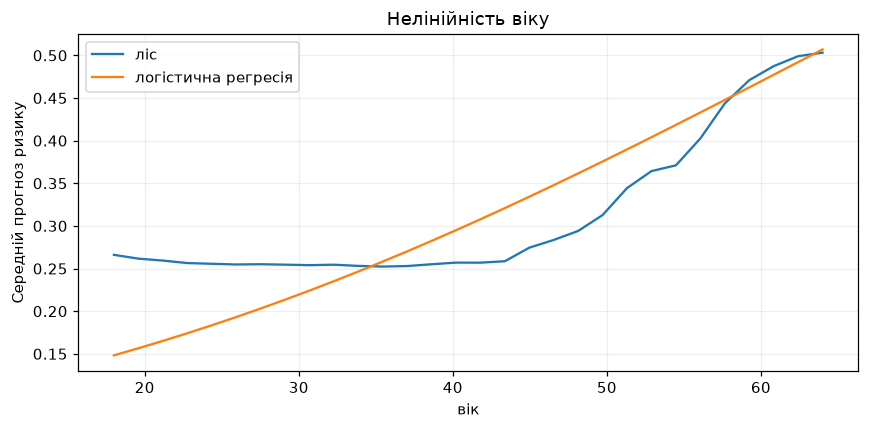

In [38]:
NONLINEAR_FEATURE = 'вік'
lr_interpret = make_pipe(Xtr, logreg()).fit(Xtr, ytr)
fig, ax = plt.subplots(figsize=(8,4))
complete = Xte.loc[Xte[NONLINEAR_FEATURE].notna()]
for estimator, label in [(model,'ліс'), (lr_interpret,'логістична регресія')]:
    p = partial_dependence(estimator, complete, [NONLINEAR_FEATURE], grid_resolution=30)
    ax.plot(p['grid_values'][0], p['average'][0], label=label)
ax.set(xlabel=NONLINEAR_FEATURE, ylabel='Середній прогноз ризику', title='Нелінійність віку')
ax.legend()
finish_plot('04_нелінійність')

In [39]:
NONLINEAR_MEANING = ('Ризик трохи спадає від молодших до середнього віку, потім різко зростає '
                     'для старших клієнтів. Це асоціація, не причинний ефект віку.')
NONLINEAR_FIX = 'Додати квадрат відхилення віку від мінімуму PDP; мінімум оцінювати лише в навчальній згортці.'
print(NONLINEAR_MEANING, NONLINEAR_FIX)

Ризик трохи спадає від молодших до середнього віку, потім різко зростає для старших клієнтів. Це асоціація, не причинний ефект віку. Додати квадрат відхилення віку від мінімуму PDP; мінімум оцінювати лише в навчальній згортці.


### Завдання 10.2б — замкніть цикл

Пояснення моделі має **повертатись у підготовку даних**. PDP показав форму —
тепер побудуйте ознаку цієї форми і виміряйте, що вона дала.

Зробіть це для **логістичної регресії**, а не для лісу: ліс цю форму і так
бачив, а лінійна модель — ні. Порівняння має бути парним.

In [40]:
training_pdp = partial_dependence(model, Xtr.loc[Xtr[NONLINEAR_FEATURE].notna()], [NONLINEAR_FEATURE], grid_resolution=25)
quad_center = float(training_pdp['grid_values'][0][np.argmin(training_pdp['average'][0])])
print('Мінімум PDP на навчальних рядках:', quad_center)

class QuadraticFromTrainingPDP(TransformerMixin, BaseEstimator):
    # Вибір центру використовує y: тому fit мусить відбуватися всередині кожної CV-згортки.
    def fit(self, X, y):
        guide = make_pipe(X, RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=2)).fit(X,y)
        p = partial_dependence(guide, X.loc[X[NONLINEAR_FEATURE].notna()], [NONLINEAR_FEATURE], grid_resolution=15)
        self.center_ = float(p['grid_values'][0][np.argmin(p['average'][0])])
        self.feature_names_in_ = np.array(X.columns, dtype=object)
        return self
    def transform(self, X):
        F = X.copy()
        F['квадрат_відхилення_віку'] = (F[NONLINEAR_FEATURE] - self.center_)**2
        return F

prototype = X4.assign(квадрат_відхилення_віку=0.)
quad_pipe = Pipeline([('quadratic', QuadraticFromTrainingPDP()), ('prediction', make_pipe(prototype, logreg()))])
start = time.perf_counter()
quad_auc = cross_val_score(quad_pipe, X4, y, cv=splits, scoring='roc_auc', error_score='raise')
quad_time = time.perf_counter()-start
quad_gain, quad_half = paired(base, quad_auc)
print('Квадратична ознака: AUC %.4f; Δ %+.4f; 95%% ДІ [%+.4f; %+.4f]; %.2f с' %
      (quad_auc.mean(), quad_gain, quad_gain-quad_half, quad_gain+quad_half, quad_time))
print('Ліс-підказка навчається заново у кожному фолді; перевіркові мітки не визначають центр.')

Мінімум PDP на навчальних рядках: 36.33333333333333


Квадратична ознака: AUC 0.8392; Δ +0.0253; 95% ДІ [+0.0120; +0.0385]; 29.78 с
Ліс-підказка навчається заново у кожному фолді; перевіркові мітки не визначають центр.


In [41]:
QUAD_GAIN = quad_gain
print('Приріст AUC:', QUAD_GAIN)

Приріст AUC: 0.02527851562624477


### Завдання 10.3 — ТРЕТЯ ХИБНА ІНТЕРПРЕТАЦІЯ

PDP **усереднює по всій вибірці**. Якщо ознака діє на різні групи клієнтів
по-різному, усереднення це приховає: протилежні ефекти взаємно погасяться,
і крива вийде майже пласкою.

Перевірте це на парі «знижка — стаж обслуговування».

1. Побудуйте звичайний PDP для `знижка_відсоток` по всій вибірці.
2. Побудуйте **ICE** (`kind='individual'`) — по кривій на кожного клієнта.
   Подивіться, чи всі криві йдуть в один бік.
3. Побудуйте PDP для `знижка_відсоток` **окремо** на двох підвибірках:
   клієнти зі стажем до 24 місяців і понад 24 місяці.

> **Важливо.** PDP і ICE рахуйте на **повній** матриці `FINAL_X`,
> а не на `Xte`. Це опитування моделі, а не оцінювання якості, тож
> використовувати всі рядки коректно — а на 30 % рядків підгрупи виходять
> замалі й криві стають шумними.

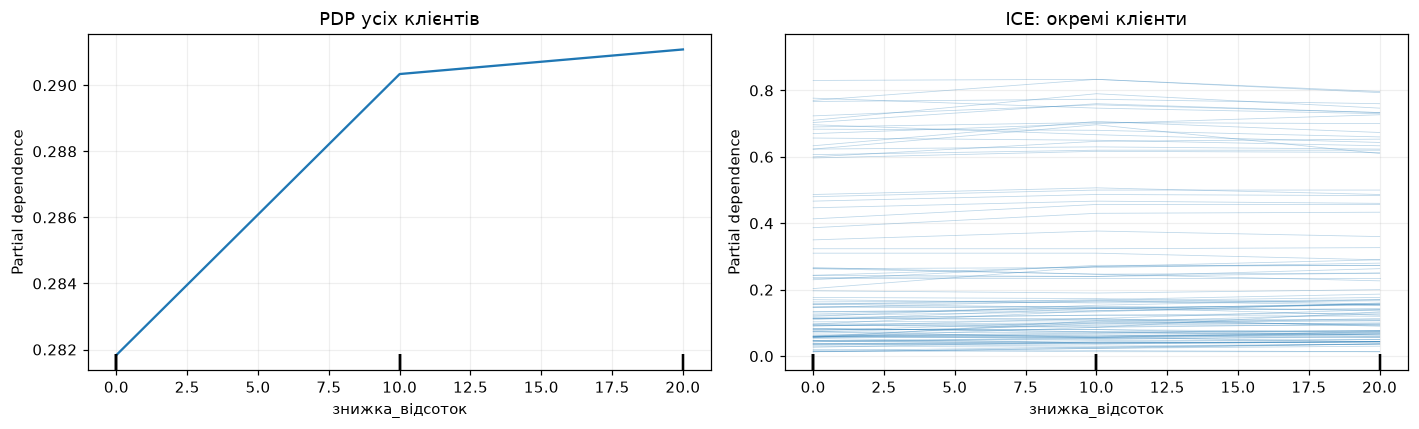

In [42]:
fig, axes = plt.subplots(1,2,figsize=(13,4))
for kind, ax in zip(['average','individual'], axes):
    PartialDependenceDisplay.from_estimator(model, FINAL_X, ['знижка_відсоток'], kind=kind,
                                           subsample=100, random_state=SEED, ax=ax)
    ax.set_title('PDP усіх клієнтів' if kind=='average' else 'ICE: окремі клієнти')
finish_plot('05_знижка_PDP_ICE')

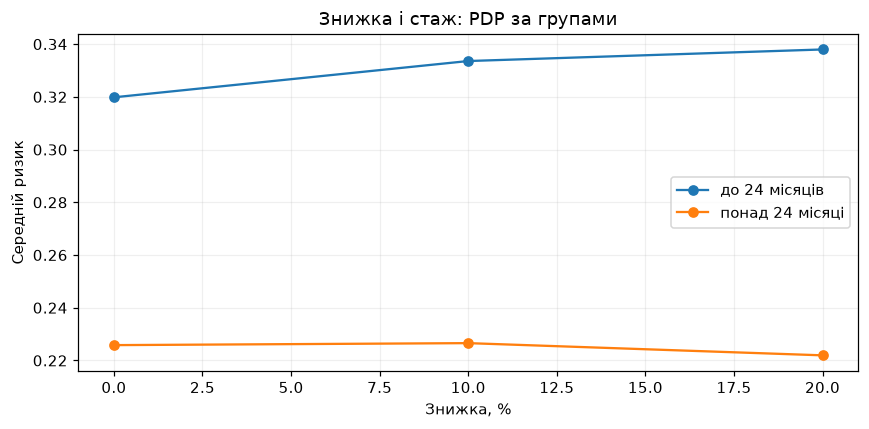

Зміна ризику від 0 до 20%: {'до 24 місяців': 0.018153846153846187, 'понад 24 місяці': -0.003876288659793753}


In [43]:
fig, ax = plt.subplots(figsize=(8,4))
discount_effects = {}
for mask, label in [(FINAL_X['місяців_обслуговування']<=24,'до 24 місяців'),
                    (FINAL_X['місяців_обслуговування']>24,'понад 24 місяці')]:
    p = partial_dependence(model, FINAL_X.loc[mask], ['знижка_відсоток'])
    ax.plot(p['grid_values'][0],p['average'][0],marker='o',label=label)
    discount_effects[label] = float(p['average'][0,-1]-p['average'][0,0])
ax.set(xlabel='Знижка, %',ylabel='Середній ризик',title='Знижка і стаж: PDP за групами')
ax.legend()
finish_plot('06_взаємодія')
print('Зміна ризику від 0 до 20%:', discount_effects)

### Завдання 10.3б — звірка з сирими даними

Перш ніж вірити графіку, перевірте його по сирій таблиці: порахуйте
**емпіричну** частку відтоку за розміром знижки окремо в кожній групі стажу.
Модель має відтворювати ту саму картину. Якщо не відтворює — питання
не до PDP, а до моделі.

In [44]:
empirical = raw.assign(стаж=np.where(raw['місяців_обслуговування']<=24,'до 24','понад 24')).groupby(['стаж','знижка_відсоток'])[TARGET].agg(['mean','size'])
display(empirical)

mean  size
стаж     знижка_відсоток                
до 24    0                0.268966   290
         10               0.376000   250
         20               0.480000   175
понад 24 0                0.235294   221
         10               0.141791   134
         20               0.069231   130

In [45]:
INTERACTION_FOUND = (f'Зміна прогнозу при 0→20% знижки: {discount_effects}. '
                      'Усереднений PDP приховує відмінності за стажем; ICE показує неоднорідність, '
                      'емпіричні частки треба порівнювати з урахуванням розмірів груп.')
BUSINESS_ACTION = ('Пропозицію знижки сегментувати за стажем і перевірити рандомізованим тестом; '
                   'зв’язок у CRM не є доведеним ефектом надання знижки.')
print(INTERACTION_FOUND, BUSINESS_ACTION)

Зміна прогнозу при 0→20% знижки: {'до 24 місяців': 0.018153846153846187, 'понад 24 місяці': -0.003876288659793753}. Усереднений PDP приховує відмінності за стажем; ICE показує неоднорідність, емпіричні частки треба порівнювати з урахуванням розмірів груп. Пропозицію знижки сегментувати за стажем і перевірити рандомізованим тестом; зв’язок у CRM не є доведеним ефектом надання знижки.


> **Що тут сталося.** PDP відповідає на питання «як змінюється
> **середній** прогноз». Якщо ефект різноспрямований, середнє близьке до нуля
> при сильних ефектах у кожній групі. ICE показує окремі криві й робить
> розбіжність видимою; PDP по підгрупах показує її кількісно.

---
## 11. Значення Шеплі

Важливість і PDP описують модель **загалом**. Відділу утримання потрібне
інше: чому **цей** клієнт отримав оцінку 0,8.

**Значення Шеплі** (SHAP) розкладають прогноз для одного об'єкта на внески
окремих ознак так, щоб сума внесків плюс базовий рівень дорівнювала самому
прогнозу. Ідея запозичена з теорії кооперативних ігор: внесок гравця —
це його середній приріст до результату по всіх можливих складах команди.

### Завдання 11.1

Порахуйте значення Шеплі для вашої моделі на перевірковій частині.

> `TreeExplainer` працює з деревами і хоче **числову матрицю**, тому
> подавайте йому вже перетворені дані: `model.named_steps['prep'].transform(Xte)`.

In [46]:
import shap
prep = model.named_steps['prep']
clf = model.named_steps['clf']
# Включаємо ВСІ відкладені рядки: найризикованіший клієнт точно не загубиться за SAMPLE.
Xte_t = prep.transform(Xte)
feat_names = prep.get_feature_names_out()
SAMPLE = len(Xte)
expl = shap.TreeExplainer(clf)
sv = expl.shap_values(Xte_t)
sv1 = sv[...,1] if np.ndim(sv)==3 else (sv[1] if isinstance(sv,list) else sv)
shap_base = float(np.asarray(expl.expected_value).ravel()[1])
assert np.allclose(shap_base + sv1.sum(axis=1), model.predict_proba(Xte)[:,1], atol=1e-6)
print('SHAP:',sv1.shape,'базовий ризик:',shap_base,'адитивність підтверджена')

C:\Users\Admin\Desktop\4Form_labs\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP: (360, 73) базовий ризик: 0.28005555555555567 адитивність підтверджена


### Завдання 11.2 — зведений графік

Побудуйте `beeswarm` (`shap.summary_plot`). Прочитайте з нього дві речі,
яких **не дає** стовпчикова діаграма важливості:

* у який бік діє ознака (колір — значення ознаки, вісь — внесок);
* чи однаковий цей напрям для всіх клієнтів.

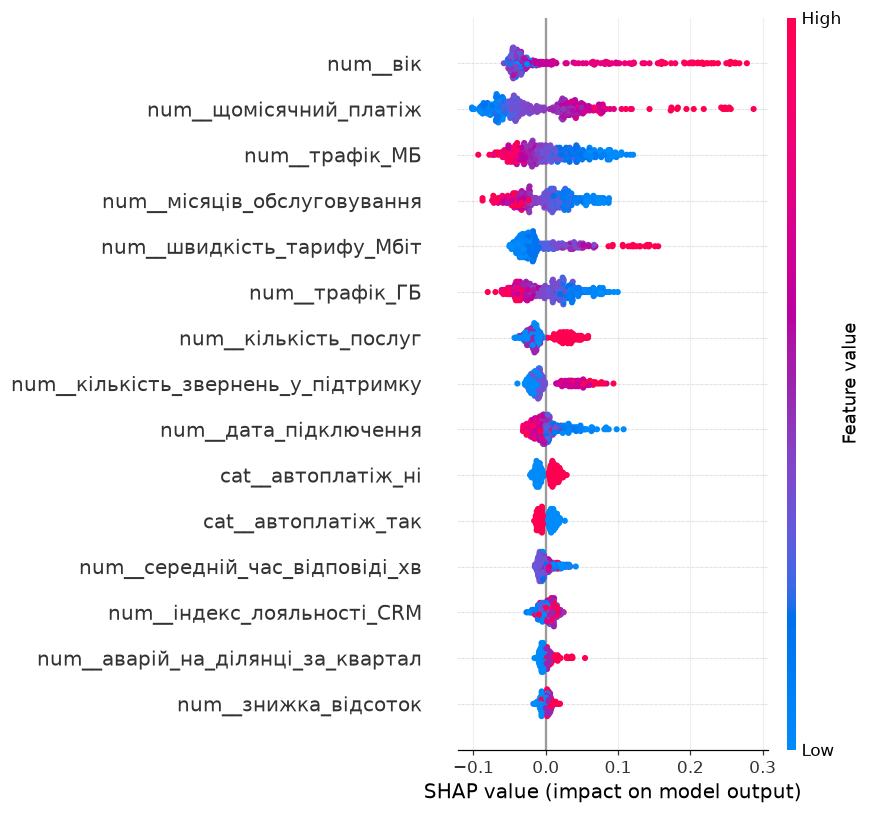

Колір показує стандартизоване значення; обидва знаки внесків означають залежність від контексту клієнта.
На цьому графіку старший вік переважно підвищує прогноз, а великий трафік і тривалий стаж знижують. Платіж і час відповіді дають внески різних знаків: вплив залежить від решти характеристик.


In [47]:
shap.summary_plot(sv1, Xte_t, feature_names=feat_names, max_display=15, show=False)
finish_plot('07_SHAP_beeswarm')
print('Колір показує стандартизоване значення; обидва знаки внесків означають залежність від контексту клієнта.')
print('На цьому графіку старший вік переважно підвищує прогноз, а великий трафік і тривалий стаж знижують. '
      'Платіж і час відповіді дають внески різних знаків: вплив залежить від решти характеристик.')

### Завдання 11.3 — пояснення для одного клієнта

Відділ утримання телефонує конкретній людині. Візьміть клієнта з
**найвищою** оцінкою ризику і поясніть його прогноз: які три ознаки
внесли найбільше і в який бік.

Напишіть пояснення **мовою, якою його можна прочитати менеджерові**, —
без назв стовпців і без слова «модель».

In [48]:
idx = int(np.argmax(model.predict_proba(Xte)[:,1]))
client_risk = float(model.predict_proba(Xte)[idx,1])
client_shap = pd.Series(sv1[idx], index=orig_names).groupby(level=0).sum()
top_contributions = client_shap.loc[client_shap.abs().sort_values(ascending=False).head(3).index]
display(top_contributions.to_frame('внесок у ймовірність'))
display(Xte.iloc[[idx]][top_contributions.index])
print('Клієнт',raw.loc[Xte.index[idx],'id_клієнта'],'ризик',client_risk)

,внесок у ймовірність
вік,0.118963
трафік_МБ,0.090871
щомісячний_платіж,0.078771


,вік,трафік_МБ,щомісячний_платіж
144,57.0,71340.8,426.95


Клієнт K20144 ризик 0.7966666666666666


In [49]:
human_labels = {'щомісячний_платіж': 'Розмір щомісячної оплати',
                'середній_час_відповіді_хв': 'Час очікування відповіді підтримки',
                'місяців_обслуговування': 'Тривалість обслуговування',
                'кількість_звернень_у_підтримку': 'Кількість звернень до підтримки',
                'трафік_ГБ': 'Обсяг спожитого інтернету', 'трафік_МБ': 'Обсяг спожитого інтернету',
                'індекс_лояльності_CRM': 'Внутрішній показник лояльності',
                'вік': 'Вік', 'аварій_на_ділянці_за_квартал': 'Аварії на ділянці мережі',
                'місто': 'Місто обслуговування', 'дата_підключення': 'Дата підключення'}
sentences = [f'Оцінений ризик розірвання договору — {client_risk:.1%}; типовий рівень у навчальній групі — {shap_base:.1%}.']
for c,v in top_contributions.items():
    label = human_labels.get(c,c.replace('_',' ')).capitalize()
    sentences.append(f'{label} {"підвищує" if v>0 else "знижує"} оцінку на {abs(v)*100:.1f} відсоткового пункту.')
EXPLANATION_FOR_MANAGER = ' '.join(sentences)
print(EXPLANATION_FOR_MANAGER)

Оцінений ризик розірвання договору — 79.7%; типовий рівень у навчальній групі — 28.0%. Вік підвищує оцінку на 11.9 відсоткового пункту. Обсяг спожитого інтернету підвищує оцінку на 9.1 відсоткового пункту. Розмір щомісячної оплати підвищує оцінку на 7.9 відсоткового пункту.


### Завдання 11.4 — ЧЕТВЕРТА ХИБНА ІНТЕРПРЕТАЦІЯ

Менеджер читає ваше пояснення і каже:

> «Зрозуміло. Значення Шеплі кажуть, що ризик тягне нагору
> **{ознака}**. Змінимо її — і клієнт лишиться».

Це найпоширеніша і найдорожча помилка в інтерпретації. Значення Шеплі
показують, **як модель користується ознакою**, а не **що станеться, якщо
ознаку змінити**. Це різні твердження, і друге з них вимагає причинного
висновку, якого в даних немає.

Наведіть із **свого** набору конкретний приклад: ознака з великим внеском,
втручання в яку нічого не дасть. Поясніть чому.

In [50]:
global_shap = pd.Series(np.abs(sv1).mean(axis=0),index=orig_names).groupby(level=0).sum().sort_values(ascending=False)
fixed = ['вік','місяців_обслуговування','місто','дата_підключення']
SHAP_NOT_CAUSAL_FEATURE = global_shap.loc[fixed].idxmax()
SHAP_NOT_CAUSAL_WHY = (f'Середній абсолютний внесок {global_shap[SHAP_NOT_CAUSAL_FEATURE]:.4f}. '
                      'Цю характеристику не можна змінити дією відділу утримання: переписування стажу, '
                      'віку чи міста в CRM не змінить історію клієнта. SHAP розкладає прогноз, а не ефект втручання.')
print(SHAP_NOT_CAUSAL_FEATURE, SHAP_NOT_CAUSAL_WHY)
display(global_shap.head(10).to_frame('mean |SHAP|'))

вік Середній абсолютний внесок 0.0599. Цю характеристику не можна змінити дією відділу утримання: переписування стажу, віку чи міста в CRM не змінить історію клієнта. SHAP розкладає прогноз, а не ефект втручання.


,mean |SHAP|
вік,0.059943
щомісячний_платіж,0.056614
трафік_МБ,0.036160
місяців_обслуговування,0.033267
код_тарифного_плану,0.033240
швидкість_тарифу_Мбіт,0.032019
трафік_ГБ,0.031561
кількість_послуг,0.023593
кількість_звернень_у_підтримку,0.023179
автоплатіж,0.021147


> **Орієнтир.** Ознаки бувають трьох видів: ті, на які можна вплинути
> (знижка, швидкість тарифу, швидкість реакції підтримки); ті, на які
> вплинути не можна (вік, місто, стаж); і ті, що є **наслідком** чогось
> іншого. Дія має сенс лише для першого виду — і лише якщо у вас є підстави
> вважати зв'язок причинним, а не збігом.

---
## 12. Зведення: чотири хибні інтерпретації

### Завдання 12.1

Заповніть таблицю своїми знахідками. Це головний результат другої частини.

In [51]:
mistakes = pd.DataFrame([
    {'№': 1, 'інструмент': 'вбудована важливість',
     'хибний висновок': 'ознака важлива, бо дерево часто по ній ріже',
     'ознака у вашому наборі': FAKE_IMPORTANT,
     'чим перевірити': 'перестановочна важливість на перевірковій частині'},
    {'№': 2, 'інструмент': 'перестановочна важливість',
     'хибний висновок': 'важливість нуль, отже ознаку можна викинути',
     'ознака у вашому наборі': ' + '.join(DUP_PAIR),
     'чим перевірити': 'прибрати одну з пари й переобчислити'},
    {'№': 3, 'інструмент': 'PDP',
     'хибний висновок': 'крива пласка, отже ознака не діє',
     'ознака у вашому наборі': 'знижка_відсоток',
     'чим перевірити': 'ICE або PDP окремо по підгрупах'},
    {'№': 4, 'інструмент': 'значення Шеплі',
     'хибний висновок': 'великий внесок, отже зміна ознаки змінить результат',
     'ознака у вашому наборі': SHAP_NOT_CAUSAL_FEATURE,
     'чим перевірити': 'питання, чи можна на цю ознаку вплинути взагалі'},
]).set_index('№')
display(mistakes)

,інструмент,хибний висновок,ознака у вашому наборі,чим перевірити
№,,,,
1,вбудована важливість,"ознака важлива, бо дерево часто по ній ріже",код_тарифного_плану,перестановочна важливість на перевірковій частині
2,перестановочна важливість,"важливість нуль, отже ознаку можна викинути",трафік_ГБ + трафік_МБ,прибрати одну з пари й переобчислити
3,PDP,"крива пласка, отже ознака не діє",знижка_відсоток,ICE або PDP окремо по підгрупах
4,значення Шеплі,"великий внесок, отже зміна ознаки змінить резу...",вік,"питання, чи можна на цю ознаку вплинути взагалі"


### Завдання 12.2 — п'ята, яку ви знайшли самі

Знайдіть у своєму аналізі ще один випадок, де пояснення можна прочитати
неправильно. Це може бути що завгодно: ознака-наслідок, що пройшла фільтри;
категорія з трьох спостережень і великим внеском; ознака, яка корелює
з артефактом збору. Опишіть його.

In [52]:
FIFTH_MISTAKE = (f'«Вилучили філію — позбулися артефакту». Насправді AUC передбачення джерела '
                 f'без самої філії дорівнює {auc_src.mean():.4f}: лишилися її проксі. '
                 'Це не доводить, що кожен проксі шкідливий, але внутрішня CV не підтверджує '
                 'перенесення в нову філію. Додатково PDP дубльованого трафіку створює '
                 'фізично неузгоджені пари ГБ/МБ, тому його форму не слід читати як ефект зміни трафіку.')
print(FIFTH_MISTAKE)

«Вилучили філію — позбулися артефакту». Насправді AUC передбачення джерела без самої філії дорівнює 0.6452: лишилися її проксі. Це не доводить, що кожен проксі шкідливий, але внутрішня CV не підтверджує перенесення в нову філію. Додатково PDP дубльованого трафіку створює фізично неузгоджені пари ГБ/МБ, тому його форму не слід читати як ефект зміни трафіку.


---
## 13. Підсумкова модель і карта дій

### Завдання 13.1

Відділ утримання може обдзвонити **100 клієнтів на тиждень** — не більше.
Отже вам потрібна не «модель узагалі», а список зі ста прізвищ.

Відсортуйте перевіркову частину за оцінкою ризику спадно, візьміть перші 100
і порахуйте: скільки з них справді пішли? Порівняйте з тим, скільки ви
знайшли б, обираючи 100 клієнтів навмання.

In [53]:
TOP_N = 100
ranked = pd.DataFrame({'id_клієнта': raw.loc[Xte.index,'id_клієнта'],
                       'ризик': model.predict_proba(Xte)[:,1], 'відтік': yte}).sort_values('ризик',ascending=False)
top100 = ranked.head(TOP_N)
top_rate = float(top100['відтік'].mean())
background_rate = float(yte.mean())
lift = top_rate/background_rate
top100.to_csv('lr6_топ100_02.csv',index=False,encoding='utf-8-sig')
print('Знайдено:',int(top100['відтік'].sum()),'із',len(top100),'; випадково очікуємо',TOP_N*background_rate,'; lift',lift)

Знайдено: 57 із 100 ; випадково очікуємо 28.055555555555557 ; lift 2.0316831683168317


In [54]:
LIFT_MEANING = (f'У топ-100 {top_rate:.1%} відтоку проти {background_rate:.1%} у відкладеній частині: '
                f'lift {lift:.3f}. Це в {lift:.2f} раза більше потенційних випадків, ніж за випадкового добору; '
                'це не число врятованих клієнтів — ефект дзвінка ще не виміряно.')
print(LIFT_MEANING)

У топ-100 57.0% відтоку проти 28.1% у відкладеній частині: lift 2.032. Це в 2.03 раза більше потенційних випадків, ніж за випадкового добору; це не число врятованих клієнтів — ефект дзвінка ще не виміряно.

> **Чому це важливіше за AUC.** AUC описує модель на всьому діапазоні
> порогів. Замовник працює в одній точці цього діапазону — там, де в нього
> вистачає людей на обдзвін. Звітуйте обидва числа.

---
## 14. Збереження результатів

In [55]:
result = {
    'студент': STUDENT_NAME,
    'номер': LIST_NUMBER,
    'варіант': VARIANT,
    'рішення': {'тип_задачі': TYPE_OF_TASK, 'метрика': METRIC, 'схема': CV_SCHEME},
    'знайдені_проблеми_даних': {
        'текст_у_числовій': PROBLEM_TEXT_IN_NUMBER,
        'excel_дата': PROBLEM_EXCEL_DATE,
        'mnar': PROBLEM_MNAR, 'сенс_пропуску': MNAR_MEANING},
    'витік': {'цільовий': TARGET_LEAK, 'оцінки_людини': HUMAN_LEAK,
              'чому_детектор_не_спіймав': HUMAN_LEAK_WHY},
    'артефакт': {'підозрюваний': SUSPECT, 'AUC_джерела': round(float(auc_src.mean()), 4),
                 'рішення': DECISION_ARTEFACT, 'аргумент': DECISION_WHY},
    'драбина_AUC': {k: round(float(v), 4) for k, v in
                    zip(ladder.index, ladder['AUC'].values)},
    'чесний_AUC': round(HONEST_AUC, 4),
    'обрана_модель': CHOSEN_MODEL,
    'хибні_інтерпретації': {
        'вбудована_важливість': FAKE_IMPORTANT,
        'дубльована_пара': DUP_PAIR,
        'нелінійна_ознака': NONLINEAR_FEATURE,
        'shap_не_причинність': SHAP_NOT_CAUSAL_FEATURE,
        'п_ята_власна': FIFTH_MISTAKE},
    'lift_топ100': None if lift is None else round(float(lift), 3),
}
result['AUC_відкладеної_частини'] = float(auc_hold)
result['AUC_SD'] = float(auc4.std())
result['квадратична_ознака_приріст'] = float(QUAD_GAIN)
result['цільовий_витік_пояснення'] = LEAK_WHY
with open('lr6_результат_%02d.json' % VARIANT, 'w', encoding='utf-8') as fh:
    json.dump(result, fh, ensure_ascii=False, indent=1)
print('збережено lr6_результат_%02d.json' % VARIANT)

збережено lr6_результат_02.json


---
## 15. Звіт

Відповідайте числами зі своїх обчислень, а не загальними словами.

1. **Яку метрику ви обрали і чому саме її?** Яку точність дала б модель
   «ніхто не піде» на ваших даних?
2. **Назвіть усі стовпці, які ви викинули**, і для кожного — момент часу,
   у який він з'являється. Який із них детектор із 5.1 не знайшов і чому?
3. **Яке ваше чесне число** і який у нього розкид? Що означає цей розкид
   для порівняння двох моделей, що відрізняються на 0,004?
4. **Чи є у ваших даних артефакт збору?** Наведіть AUC передбачення джерела
   і скажіть, чи можна цій моделі довіряти в іншій філії.
5. **Що дало більше — нові ознаки чи складніша модель?** Наведіть обидва
   прирости з довірчими інтервалами і час обчислень.
6. **Яку ознаку вбудована важливість назвала важливою помилково?**
   Чому дерева так роблять?
7. **Що сталося з дубльованою парою** при перестановочній важливості
   і чому це не вада методу?
8. **Яка ознака має немонотонний вплив?** Чи побачила б його логістична
   регресія без вашого втручання?
9. **Де PDP збрехав через усереднення** і що показав ICE?
10. **Наведіть приклад ознаки з великим внеском за Шеплі, втручання в яку
    нічого не дасть.** Поясніть різницю між «модель цим користується»
    і «це причина».
11. **Що ви скажете замовникові**, який просить за цією моделлю обдзвонити
    100 клієнтів? Назвіть lift і одне застереження.

### Декларація про використання штучного інтелекту

Зазначте, чи користувались ШІ-асистентом, для чого саме і що перевіряли
самостійно. Використання дозволене; невказане використання — ні.

In [56]:
mg, mh = model_gains[CHOSEN_MODEL]
REPORT = f"""
1. Бінарна класифікація; метрика ROC AUC оцінює ранжування без порога. Частка відтоку {y.mean():.1%};
   тривіальна відповідь «ніхто не піде» дає accuracy {1-y.mean():.1%} при нульовій повноті.
2. Вилучено id_клієнта (відомий при реєстрації, але технічний ідентифікатор),
   код_причини_закриття і дата_розірвання (з’являються після рішення розірвати договір),
   оцінка_ризику_менеджером (ретроспективне судження після спостереження поведінки), філія
   (відоме при підключенні джерело із підозрілими правилами обліку). {HUMAN_LEAK_WHY}
   Драбина AUC: {auc_naive.mean():.4f} → {auc2.mean():.4f} → {auc3.mean():.4f} → {auc4.mean():.4f}.
3. Внутрішня чесна оцінка логістичної регресії {HONEST_AUC:.4f} ± {auc4.std():.4f} (SD 20 згорток).
   Це розкид, не довірчий інтервал. Різниця 0,004 сама по собі не обґрунтовує перевагу;
   застосовано парні порівняння з поправкою на залежність CV. Ліс на діагностичних 30%: {auc_hold:.4f}.
4. Ф-01/Ф-02 мають частки відтоку {branch_rates.iloc[0]['mean']:.3f}/{branch_rates.iloc[1]['mean']:.3f},
   інші приблизно 0,19–0,21. AUC джерела {auc_src.mean():.4f}. Це сигнал аудиту збору.
   {DECISION_WHY}
5. {FEATURES_VS_MODEL} Інтервали наближені, corrected resampled t; підбір гіперпараметрів не проводився.
6. {FAKE_IMPORTANT}: MDI {gini_imp[FAKE_IMPORTANT]:.4f}, permutation {perm_imp[FAKE_IMPORTANT]:+.4f},
   місце {fake_rank} за MDI. Висока MDI за майже нульової перевіркової важливості — пастка.
   {FAKE_IMPORTANT_WHY}
7. {DUP_EXPLANATION}
8. {NONLINEAR_FEATURE}: {NONLINEAR_MEANING} Логістична регресія на сирому віці монотонна.
   Квадрат із центром, визначеним у кожній навчальній згортці, дав ΔAUC {QUAD_GAIN:+.4f},
   95% ДІ [{QUAD_GAIN-quad_half:+.4f}; {QUAD_GAIN+quad_half:+.4f}], час {quad_time:.2f} с.
9. {INTERACTION_FOUND} {BUSINESS_ACTION}
10. {SHAP_NOT_CAUSAL_FEATURE}: {SHAP_NOT_CAUSAL_WHY}
11. {LIFT_MEANING} На новій філії/у наступному кварталі якість може змінитися;
    перед використанням потрібні зовнішня перевірка і експеримент ефективності утримання.

П’ята хибна інтерпретація: {FIFTH_MISTAKE}

Декларація про використання ШІ:
Використано Codex для реалізації обробки, конвеєрів, перевірки витоку, експериментів,
побудови графіків SHAP/PDP/ICE та формування звіту. Числа отримано виконанням коду;
автоматично перевірено розбір дат, відповідність пропусків зверненням, відсутність витоків
у списку ознак, адитивність SHAP і виконання ноутбука згори вниз.
Я самостійно перечитав увесь код і пояснення, перевірив результати обчислень,
таблиці, графіки та висновки. Розібрався у використаних методах і можу пояснити
логіку виконаних кроків та інтерпретацію отриманих результатів.
"""
print(REPORT)
Path('lr6_звіт_02.md').write_text(REPORT, encoding='utf-8')


1. Бінарна класифікація; метрика ROC AUC оцінює ранжування без порога. Частка відтоку 28.0%;
   тривіальна відповідь «ніхто не піде» дає accuracy 72.0% при нульовій повноті.
2. Вилучено id_клієнта (відомий при реєстрації, але технічний ідентифікатор),
   код_причини_закриття і дата_розірвання (з’являються після рішення розірвати договір),
   оцінка_ризику_менеджером (ретроспективне судження після спостереження поведінки), філія
   (відоме при підключенні джерело із підозрілими правилами обліку). Оцінка заповнена для всіх, тому індикатор наявності сталий. Менеджер оцінює ризик після спостереження поведінки клієнта; у момент першого звернення цю ретроспективну оцінку використати не можна.
   Драбина AUC: 1.0000 → 0.9665 → 0.8635 → 0.8140.
3. Внутрішня чесна оцінка логістичної регресії 0.8140 ± 0.0238 (SD 20 згорток).
   Це розкид, не довірчий інтервал. Різниця 0,004 сама по собі не обґрунтовує перевагу;
   застосовано парні порівняння з поправкою на залежність CV. Ліс на діагностичних 3

4450

---
### Перед здачею

* **Kernel → Restart & Run All** — ноутбук має пройти згори вниз без помилок.
* Усі `assert` зелені, жодного `NotImplementedError`.
* Файл `lr6_результат_NN.json` створено.
* У звіті є числа, а не загальні формулювання.